Imports and parameters

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt

from tls_sync import HeomSolver, MarkovianSolver, SemiclassicalSolver, TempoSolver
from tls_sync.model import TLSChainModel, Bath, TLSCavityModel, SemiclassicalCavityModel
from tls_sync.plotting import plot_bloch_sphere

 # model params
tls_freq = [1.0]  # GHZ frequency of the bath modes (normalized)
Omega_amp = 60*tls_freq[0]  # GHz frequency of the driving field
T_drive = 3.0

# bath params
cutoff = tls_freq[0] # GHz cut off frequency
lam = tls_freq[0]  # coupling strength
T = 0.5  # K temperature

# solver params
T_total = T_drive
dt = T_drive / 1e3

omegad = Omega_amp/2.4048  # GHz frequency of the driving field (resonant)

# cavity mode
omega_c = 4.0

# decay
dissipation = 0.002

# initial states
psis = [
    (qt.basis(2,1)+qt.basis(2,0)).unit(),
    (qt.basis(2,1)+2.*qt.basis(2,0)).unit(),
    (2.*qt.basis(2,1)+qt.basis(2,0)).unit(),
    ((2j+.3)*qt.basis(2,1) + np.sqrt(2*2 + .3*.3)*qt.basis(2,0)).unit(),
    ((2j+.3)*qt.basis(2,0) + np.sqrt(2*2 + .3*.3)*qt.basis(2,1)).unit()
]

Markovian Simulation

/Users/sergleonov/projects/tls_synchronization/.venv/lib/python3.12/site-packages/qutip/core/coefficient.py:199: FutureWarning: The signature f(t, args) is deprecated and will be removed in QuTiP 5.5. Please update your function to the pythonic signature f(t, **kwargs) to maintain compatibility.
  op = FunctionCoefficient(base, args.copy(), style=function_style)


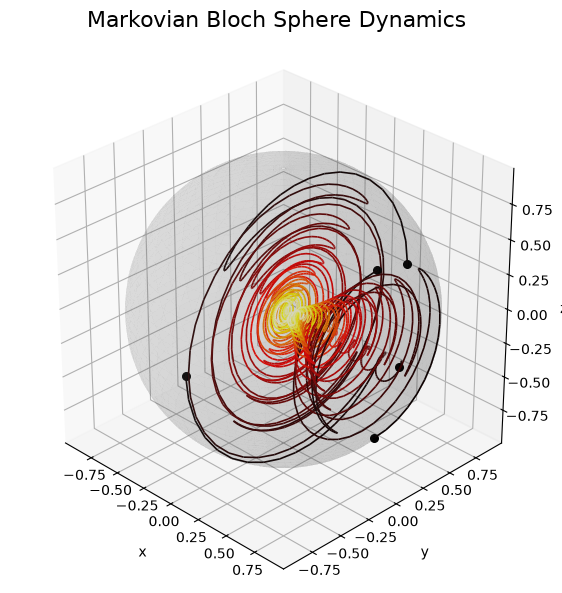

In [10]:
markov_bath = Bath(
        sd_type="drude",
        coupling=lam,
        cutoff=cutoff,
        temperature=T
    )

# init HEOM/Lindblad model
markov_model = TLSChainModel(
    omega_tls=tls_freq,
    Omega_amp=Omega_amp,
    T_drive=T_total,
    n_tls=1,
    bath=markov_bath
)

markov = MarkovianSolver(markov_model, T_total=T_total, dt=dt)
e_ops = [sum(markov.ops.sx), sum(markov.ops.sy),sum(markov.ops.sz)]
fig, axs= None, None
for psi in psis:
    rho0 = qt.ket2dm(psi)
    markov_res = markov.single_run(omegad, rho0=rho0, e_ops=e_ops)
    fig, axs = plot_bloch_sphere([markov_res], title="Markovian Bloch Sphere Dynamics", tmax=T_total, fig=fig, axs=axs)

plt.tight_layout()
plt.savefig("../../figs/cycle_figures/bloch_initial_states_markov.png", dpi=300)

HEOM Simulation with Drude-Lorentz spectral density

/Users/sergleonov/projects/tls_synchronization/.venv/lib/python3.12/site-packages/qutip/core/coefficient.py:199: FutureWarning: The signature f(t, args) is deprecated and will be removed in QuTiP 5.5. Please update your function to the pythonic signature f(t, **kwargs) to maintain compatibility.
  op = FunctionCoefficient(base, args.copy(), style=function_style)


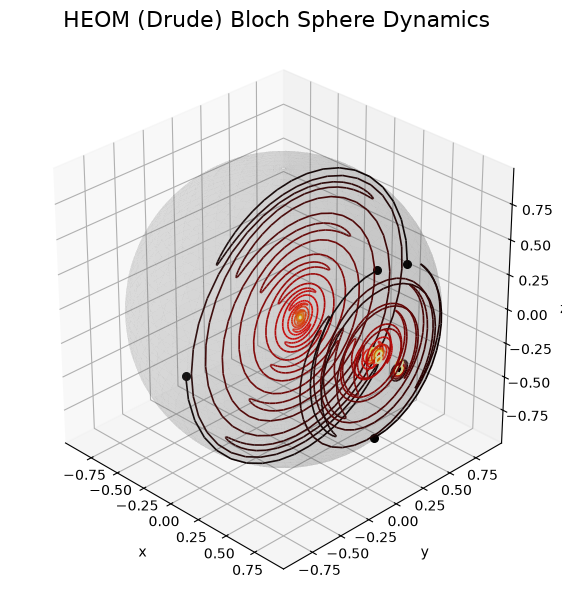

In [23]:
heom_bath = Bath(
    sd_type="drude",
    coupling=lam,
    cutoff=cutoff,
    temperature=T
)

# init HEOM/Lindblad model
heom_model = TLSChainModel(
    omega_tls=tls_freq,
    Omega_amp=Omega_amp,
    T_drive=T_total,
    n_tls=1,
    bath=heom_bath
)

heom = HeomSolver(heom_model, T_total=T_total, dt=dt, Nk=3)
e_ops = [sum(heom.ops.sx), sum(heom.ops.sy),sum(heom.ops.sz)]
fig, axs= None, None
for psi in psis:
    rho0 = qt.ket2dm(psi)
    heom_res = heom.single_run(omegad, rho0=rho0, e_ops=e_ops)
    fig, axs = plot_bloch_sphere([heom_res], title="HEOM (Drude) Bloch Sphere Dynamics", tmax=T_total, fig=fig, axs=axs)

plt.tight_layout()
plt.savefig("../../figs/cycle_figures/bloch_initial_states_heom_drude.png", dpi=300)

Tiered Simulation

/Users/sergleonov/projects/tls_synchronization/.venv/lib/python3.12/site-packages/qutip/core/coefficient.py:199: FutureWarning: The signature f(t, args) is deprecated and will be removed in QuTiP 5.5. Please update your function to the pythonic signature f(t, **kwargs) to maintain compatibility.
  op = FunctionCoefficient(base, args.copy(), style=function_style)


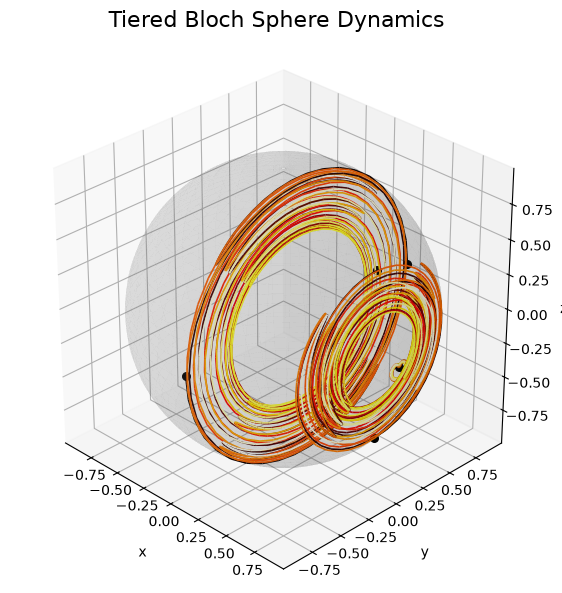

In [ ]:
n_fock = 10
# init tiered
tiered_model = TLSCavityModel(
    omega_tls=tls_freq,
    Omega_amp=Omega_amp,
    T_drive=T_drive,
    omega_c=omega_c,
    g=lam,                       # mode coupling
    Nb=n_fock,                     # fock number
    gamma=dissipation,         # tls relaxation
    temperature=T,
    n_tls=1,
)
tiered = MarkovianSolver(tiered_model, T_total=T_total, dt=dt)
e_ops_tiered = [sum(tiered.ops.sx), sum(tiered.ops.sy),sum(tiered.ops.sz)]
fig, axs= None, None
for psi in psis:
    psi = qt.tensor(psi, qt.basis(n_fock,0))
    rho0 = qt.ket2dm(psi)
    tiered_res = tiered.single_run(omegad, rho0=rho0, e_ops=e_ops_tiered)
    fig, axs = plot_bloch_sphere([tiered_res], title="Tiered Bloch Sphere Dynamics", tmax=T_total, fig=fig, axs=axs)

plt.tight_layout()
plt.savefig(f"../../figs/cycle_figures/bloch_initial_states_tiered_diss{dissipation}.png", dpi=300)

Semiclassical Simulation

SemiclassicalSolver sweep: 100%|██████████| 10000/10000 [00:00<00:00, 10401.93it/s]


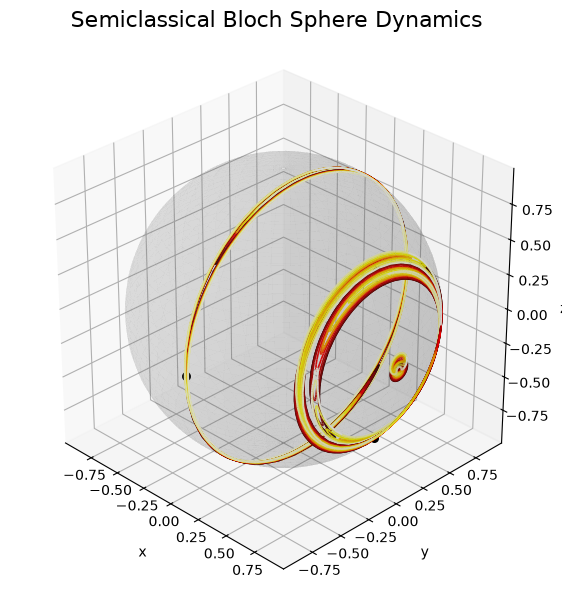

In [18]:
# init semiclassical
semiclassical_model = SemiclassicalCavityModel(
    omega_tls=tls_freq,
    Omega_amp=Omega_amp,
    T_drive=T_drive,
    omega_c=omega_c,
    g=lam,
    kappa=0.001,               # cavity leakage
    eta=0.0,
    gamma=dissipation,         # TLS relaxation rate
    gamma_phi=dissipation / 10.0,
    temperature=T,
    n_tls=1,
)

semi = SemiclassicalSolver(semiclassical_model, T_total=T_total, dt=dt/10.0, dt_output=dt)
e_ops_semi = [sum(semi.ops.sx), sum(semi.ops.sy),sum(semi.ops.sz)]
fig, axs= None, None
for psi in psis:
    rho0 = qt.ket2dm(psi)
    semi_res = semi.single_run(omegad, rho0=rho0.full(), e_ops=e_ops_semi)
    fig, axs = plot_bloch_sphere([semi_res], title="Semiclassical Bloch Sphere Dynamics", tmax=T_total, fig=fig, axs=axs)

plt.tight_layout()
plt.savefig(f"../../figs/cycle_figures/bloch_initial_states_semi_diss{dissipation}.png", dpi=300)

TEMPO Simulations

In [22]:
ohmicity = 3.0
power_bath = Bath(
    sd_type="power",
    ohmicity=ohmicity,
    coupling=lam,
    cutoff=cutoff,
    temperature=T
)

# init model
power_model = TLSChainModel(
    omega_tls=tls_freq,
    Omega_amp=Omega_amp,
    T_drive=T_total,
    n_tls=1,
    bath=power_bath
)

tempo = TempoSolver(power_model, T_total=T_total, dt=dt, tcut=2.5, epsrel=1e-4)
e_ops_tempo = [sum(tempo.ops.sx), sum(tempo.ops.sy),sum(tempo.ops.sz)]
fig, axs= None, None
for psi in psis:
    rho0 = qt.ket2dm(psi)
    tempo_res = tempo.single_run(omegad, rho0=rho0.full(), e_ops=e_ops_tempo)
    fig, axs = plot_bloch_sphere([semi_res], title=f"TEMPO (s = {ohmicity:.0}) Bloch Sphere Dynamics", tmax=T_total, fig=fig, axs=axs)

plt.tight_layout()
plt.savefig(f"../../figs/cycle_figures/bloch_initial_states_tempo_ohm{ohmicity}.png", dpi=300)

--> PT-TEMPO computation:
  2.1%   21 of 1000 [----------------------------------------] 00:00:03
Elapsed time: 3.2s


KeyboardInterrupt: 